# Data Cleaning and Preparation – Netflix Movies and TV Shows

**Internship:** SWYNEX Technologies – Task 1  
**Project Domain:** Data Analytics  
**Dataset:** Netflix Movies and TV Shows  
**Tools Used:** Python, Pandas, NumPy, Matplotlib, Seaborn and Google Colab

## 1. Project Overview

Data cleaning is an important step in the data analysis process. Raw datasets may contain missing values, inconsistent entries, incorrect data types and formatting issues that can affect the accuracy of analysis.

In this project, I worked with the Netflix Movies and TV Shows dataset to identify and resolve data-quality issues using Python and Pandas.

## 2. Project Objectives

- Identify and examine missing values.
- Detect duplicate records.
- Identify inconsistent and incorrectly placed values.
- Handle missing information appropriately.
- Standardize text and duration formats.
- Convert columns into suitable data types.
- Validate the cleaned dataset.
- Export the final cleaned dataset.

## 3. Dataset Description

The dataset contains information about movies and television shows available on Netflix.

**Initial dataset dimensions:**
- Total records: 8,807
- Total columns: 12
- Dataset format: CSV

**Dataset source:** [Netflix Movies and TV Shows – Kaggle](https://www.kaggle.com/datasets/shivamb/netflix-shows)

1. Importing Libraries and Loading the Raw Dataset

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Load Kaggle dataset
df_raw = pd.read_csv('/content/netflix_titles.csv.csv')

# Preserve original data
df_raw_original = df_raw.copy()

print("Dataset loaded successfully!")
print("Shape:", df_raw.shape)

display(df_raw.head())

Dataset loaded successfully!
Shape: (8807, 12)


,show_id,type,title,director,cast,country,date_added,release_year,rating,duration,listed_in,description
0,s1,Movie,Dick Johnson Is Dead,Kirsten Johnson,NaN,United States,"September 25, 2021",2020,PG-13,90 min,Documentaries,"As her father nears the end of his life, filmm..."
1,s2,TV Show,Blood & Water,NaN,"Ama Qamata, Khosi Ngema, Gail Mabalane, Thaban...",South Africa,"September 24, 2021",2021,TV-MA,2 Seasons,"International TV Shows, TV Dramas, TV Mysteries","After crossing paths at a party, a Cape Town t..."
2,s3,TV Show,Ganglands,Julien Leclercq,"Sami Bouajila, Tracy Gotoas, Samuel Jouy, Nabi...",NaN,"September 24, 2021",2021,TV-MA,1 Season,"Crime TV Shows, International TV Shows, TV Act...",To protect his family from a powerful drug lor...
3,s4,TV Show,Jailbirds New Orleans,NaN,NaN,NaN,"September 24, 2021",2021,TV-MA,1 Season,"Docuseries, Reality TV","Feuds, flirtations and toilet talk go down amo..."
4,s5,TV Show,Kota Factory,NaN,"Mayur More, Jitendra Kumar, Ranjan Raj, Alam K...",India,"September 24, 2021",2021,TV-MA,2 Seasons,"International TV Shows, Romantic TV Shows, TV ...",In a city of coaching centers known to train I...


2. Initial Dataset Inspection and Data Quality Assessment


In [3]:
print("Dataset Information:")
df_raw.info()

print("\nMissing Values:")
print(df_raw.isnull().sum())

print("\nDuplicate Records:")
print(df_raw.duplicated().sum())

print("\nStatistical Summary:")
display(df_raw.describe(include='all').T)

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8807 entries, 0 to 8806
Data columns (total 12 columns):
 #   Column        Non-Null Count  Dtype 
---  ------        --------------  ----- 
 0   show_id       8807 non-null   object
 1   type          8807 non-null   object
 2   title         8807 non-null   object
 3   director      6173 non-null   object
 4   cast          7982 non-null   object
 5   country       7976 non-null   object
 6   date_added    8797 non-null   object
 7   release_year  8807 non-null   int64 
 8   rating        8803 non-null   object
 9   duration      8804 non-null   object
 10  listed_in     8807 non-null   object
 11  description   8807 non-null   object
dtypes: int64(1), object(11)
memory usage: 825.8+ KB

Missing Values:
show_id            0
type               0
title              0
director        2634
cast             825
country          831
date_added        10
release_year       0
rating             4
duration           3
list

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
show_id,8807,8807,s1,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
type,8807,2,Movie,6131,NaN,NaN,NaN,NaN,NaN,NaN,NaN
title,8807,8807,Dick Johnson Is Dead,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
director,6173,4528,Rajiv Chilaka,19,NaN,NaN,NaN,NaN,NaN,NaN,NaN
cast,7982,7692,David Attenborough,19,NaN,NaN,NaN,NaN,NaN,NaN,NaN
country,7976,748,United States,2818,NaN,NaN,NaN,NaN,NaN,NaN,NaN
date_added,8797,1767,"January 1, 2020",109,NaN,NaN,NaN,NaN,NaN,NaN,NaN
release_year,8807.0,NaN,NaN,NaN,2014.180198,8.819312,1925.0,2013.0,2017.0,2019.0,2021.0
rating,8803,17,TV-MA,3207,NaN,NaN,NaN,NaN,NaN,NaN,NaN
duration,8804,220,1 Season,1793,NaN,NaN,NaN,NaN,NaN,NaN,NaN


3. Missing Value Analysis

In [4]:
# Missing value analysis

missing_values = df_raw.isnull().sum()

missing_report = pd.DataFrame({
    'Missing Count': missing_values,
    'Missing Percentage': (missing_values / len(df_raw)) * 100
})

missing_report = missing_report.sort_values(
    by='Missing Count', ascending=False
)

print("MISSING VALUE REPORT")
display(missing_report)

MISSING VALUE REPORT


,Missing Count,Missing Percentage
director,2634,29.908028
country,831,9.435676
cast,825,9.367549
date_added,10,0.113546
rating,4,0.045418
duration,3,0.034064
show_id,0,0.000000
type,0,0.000000
title,0,0.000000
release_year,0,0.000000


4. Duplicate Record Analysis

In [5]:
# Duplicate record analysis

total_duplicates = df_raw.duplicated().sum()

print("Total duplicate records:", total_duplicates)

# Check duplicate show IDs
duplicate_ids = df_raw['show_id'].duplicated().sum()

print("Duplicate show IDs:", duplicate_ids)

Total duplicate records: 0
Duplicate show IDs: 0


5. Data type analysis

In [6]:
# Data type analysis

datatype_report = pd.DataFrame({
    'Column': df_raw.columns,
    'Data Type': df_raw.dtypes.astype(str).values,
    'Unique Values': df_raw.nunique().values
})

display(datatype_report)

,Column,Data Type,Unique Values
0,show_id,object,8807
1,type,object,2
2,title,object,8807
3,director,object,4528
4,cast,object,7692
5,country,object,748
6,date_added,object,1767
7,release_year,int64,74
8,rating,object,17
9,duration,object,220


6. Checking for Inconsistent Whitespace in Text Columns

In [7]:
# Check leading and trailing whitespace

for col in df_raw.select_dtypes(include='object').columns:
    whitespace_count = (
        df_raw[col].dropna() != df_raw[col].dropna().str.strip()
    ).sum()

    if whitespace_count > 0:
        print(f"{col}: {whitespace_count} values contain extra whitespace")

title: 1 values contain extra whitespace
date_added: 88 values contain extra whitespace


7. Examining Unique Categorical Values

In [8]:
# Examine unique categorical values

categorical_columns = [
    'type', 'rating', 'country'
]

for col in categorical_columns:
    print(f"\nUnique values in {col}:")
    print(df_raw[col].value_counts(dropna=False).head(20))


Unique values in type:
type
Movie      6131
TV Show    2676
Name: count, dtype: int64

Unique values in rating:
rating
TV-MA       3207
TV-14       2160
TV-PG        863
R            799
PG-13        490
TV-Y7        334
TV-Y         307
PG           287
TV-G         220
NR            80
G             41
TV-Y7-FV       6
NaN            4
NC-17          3
UR             3
66 min         1
74 min         1
84 min         1
Name: count, dtype: int64

Unique values in country:
country
United States                    2818
India                             972
NaN                               831
United Kingdom                    419
Japan                             245
South Korea                       199
Canada                            181
Spain                             145
France                            124
Mexico                            110
Egypt                             106
Turkey                            105
Nigeria                            95
Australia          

8. Visualizing Missing Values in the Dataset

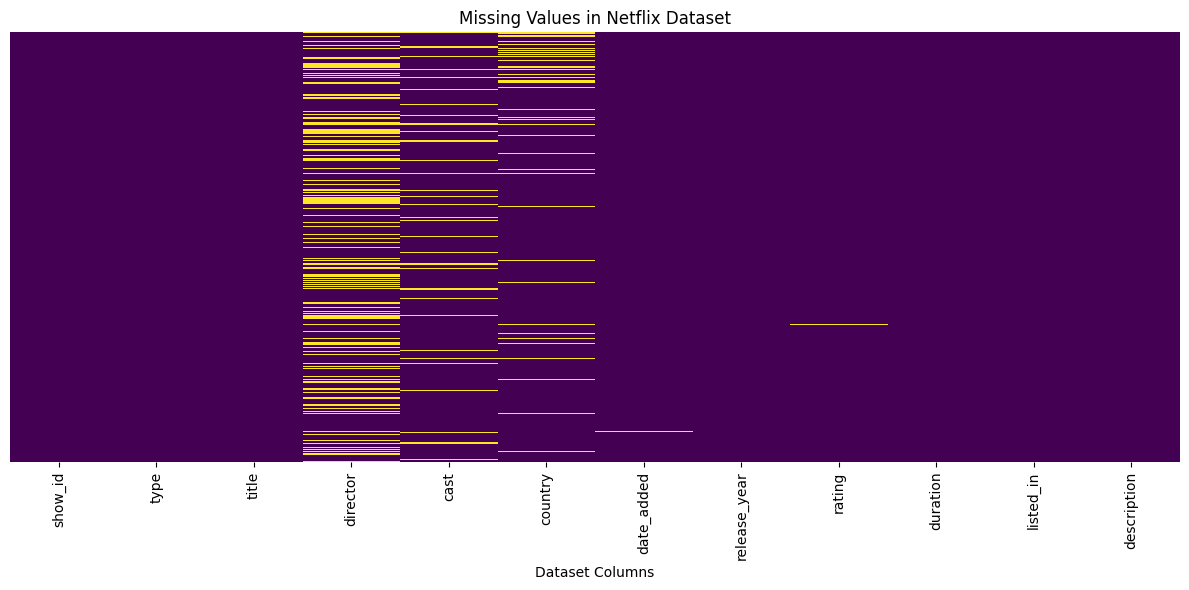

In [9]:
plt.figure(figsize=(12, 6))

sns.heatmap(
    df_raw.isnull(),
    cbar=False,
    yticklabels=False,
    cmap='viridis'
)

plt.title('Missing Values in Netflix Dataset')
plt.xlabel('Dataset Columns')
plt.tight_layout()
plt.show()

 9. Finding records with incorrect rating values

In [10]:
# Find records with incorrect rating values
invalid_ratings = df_raw[
    df_raw['rating'].isin(['66 min', '74 min', '84 min'])
]

print("RECORDS WITH POSSIBLE INCORRECT RATINGS:")
display(invalid_ratings)

# Find records with missing duration
print("\nRECORDS WITH MISSING DURATION:")
display(df_raw[df_raw['duration'].isnull()])

# Find records with missing rating
print("\nRECORDS WITH MISSING RATING:")
display(df_raw[df_raw['rating'].isnull()])

RECORDS WITH POSSIBLE INCORRECT RATINGS:


,show_id,type,title,director,cast,country,date_added,release_year,rating,duration,listed_in,description
5541,s5542,Movie,Louis C.K. 2017,Louis C.K.,Louis C.K.,United States,"April 4, 2017",2017,74 min,NaN,Movies,"Louis C.K. muses on religion, eternal love, gi..."
5794,s5795,Movie,Louis C.K.: Hilarious,Louis C.K.,Louis C.K.,United States,"September 16, 2016",2010,84 min,NaN,Movies,Emmy-winning comedy writer Louis C.K. brings h...
5813,s5814,Movie,Louis C.K.: Live at the Comedy Store,Louis C.K.,Louis C.K.,United States,"August 15, 2016",2015,66 min,NaN,Movies,The comic puts his trademark hilarious/thought...



RECORDS WITH MISSING DURATION:


,show_id,type,title,director,cast,country,date_added,release_year,rating,duration,listed_in,description
5541,s5542,Movie,Louis C.K. 2017,Louis C.K.,Louis C.K.,United States,"April 4, 2017",2017,74 min,NaN,Movies,"Louis C.K. muses on religion, eternal love, gi..."
5794,s5795,Movie,Louis C.K.: Hilarious,Louis C.K.,Louis C.K.,United States,"September 16, 2016",2010,84 min,NaN,Movies,Emmy-winning comedy writer Louis C.K. brings h...
5813,s5814,Movie,Louis C.K.: Live at the Comedy Store,Louis C.K.,Louis C.K.,United States,"August 15, 2016",2015,66 min,NaN,Movies,The comic puts his trademark hilarious/thought...



RECORDS WITH MISSING RATING:


,show_id,type,title,director,cast,country,date_added,release_year,rating,duration,listed_in,description
5989,s5990,Movie,13TH: A Conversation with Oprah Winfrey & Ava ...,NaN,"Oprah Winfrey, Ava DuVernay",NaN,"January 26, 2017",2017,NaN,37 min,Movies,Oprah Winfrey sits down with director Ava DuVe...
6827,s6828,TV Show,Gargantia on the Verdurous Planet,NaN,"Kaito Ishikawa, Hisako Kanemoto, Ai Kayano, Ka...",Japan,"December 1, 2016",2013,NaN,1 Season,"Anime Series, International TV Shows","After falling through a wormhole, a space-dwel..."
7312,s7313,TV Show,Little Lunch,NaN,"Flynn Curry, Olivia Deeble, Madison Lu, Oisín ...",Australia,"February 1, 2018",2015,NaN,1 Season,"Kids' TV, TV Comedies","Adopting a child's perspective, this show take..."
7537,s7538,Movie,My Honor Was Loyalty,Alessandro Pepe,"Leone Frisa, Paolo Vaccarino, Francesco Miglio...",Italy,"March 1, 2017",2015,NaN,115 min,Dramas,"Amid the chaos and horror of World War II, a c..."


10. Correcting Misplaced Duration Values in the Rating Column

In [11]:
# Create a working copy for cleaning
df_clean = df_raw.copy()

# Identify records where duration is missing
# but rating contains a duration value
mask = (
    df_clean['duration'].isnull() &
    df_clean['rating'].str.contains(r'^\d+\s+min$', na=False)
)

# Move the misplaced values from rating to duration
df_clean.loc[mask, 'duration'] = df_clean.loc[mask, 'rating']

# Set the incorrect rating entries to missing
df_clean.loc[mask, 'rating'] = pd.NA

print("Number of corrected records:", mask.sum())

# Verify the corrections
display(
    df_clean.loc[
        df_clean['title'].str.contains('Louis C.K.', case=False, na=False),
        ['title', 'rating', 'duration']
    ]
)

Number of corrected records: 3


,title,rating,duration
5541,Louis C.K. 2017,<NA>,74 min
5794,Louis C.K.: Hilarious,<NA>,84 min
5813,Louis C.K.: Live at the Comedy Store,<NA>,66 min


11. Cleaning Text Columns, Handling Missing Values and Converting Date Format

In [12]:


# 1. Remove leading and trailing whitespace
text_columns = df_clean.select_dtypes(include='object').columns

for col in text_columns:
    df_clean[col] = df_clean[col].str.strip()

# 2. Fill missing values in selected columns
df_clean['director'] = df_clean['director'].fillna('Not Available')
df_clean['cast'] = df_clean['cast'].fillna('Not Available')
df_clean['country'] = df_clean['country'].fillna('Not Available')
df_clean['rating'] = df_clean['rating'].fillna('Not Specified')

# 3. Convert date_added into datetime format
df_clean['date_added'] = pd.to_datetime(
    df_clean['date_added'],
    format='%B %d, %Y',
    errors='coerce'
)

# 4. Display updated missing value report
missing_after = pd.DataFrame({
    'Missing Count': df_clean.isnull().sum(),
    'Missing Percentage': (df_clean.isnull().sum() / len(df_clean)) * 100
})

print("MISSING VALUE REPORT AFTER CLEANING:")
display(missing_after[missing_after['Missing Count'] > 0])

print("\nUPDATED DATA TYPES:")
print(df_clean.dtypes)

MISSING VALUE REPORT AFTER CLEANING:


,Missing Count,Missing Percentage
date_added,10,0.113546



UPDATED DATA TYPES:
show_id                 object
type                    object
title                   object
director                object
cast                    object
country                 object
date_added      datetime64[ns]
release_year             int64
rating                  object
duration                object
listed_in               object
description             object
dtype: object


12. STANDARDIZE DURATION

In [13]:


# Extract numerical duration
df_clean['duration_value'] = pd.to_numeric(
    df_clean['duration'].str.extract(r'(\d+)')[0],
    errors='coerce'
).astype('Int64')

# Extract duration unit
df_clean['duration_unit'] = (
    df_clean['duration']
    .str.extract(r'([A-Za-z]+)$')[0]
    .str.lower()
)

# Standardize duration units
df_clean['duration_unit'] = df_clean['duration_unit'].replace({
    'min': 'min',
    'season': 'seasons',
    'seasons': 'seasons'
})

# Display sample results
print("STANDARDIZED DURATION:")
display(
    df_clean[['type', 'title', 'duration',
              'duration_value', 'duration_unit']].head(15)
)

# Check missing duration values
print("\nMissing duration values:")
print(df_clean['duration_value'].isnull().sum())

print("\nDuration unit counts:")
print(df_clean['duration_unit'].value_counts(dropna=False))

STANDARDIZED DURATION:


,type,title,duration,duration_value,duration_unit
0,Movie,Dick Johnson Is Dead,90 min,90,min
1,TV Show,Blood & Water,2 Seasons,2,seasons
2,TV Show,Ganglands,1 Season,1,seasons
3,TV Show,Jailbirds New Orleans,1 Season,1,seasons
4,TV Show,Kota Factory,2 Seasons,2,seasons
5,TV Show,Midnight Mass,1 Season,1,seasons
6,Movie,My Little Pony: A New Generation,91 min,91,min
7,Movie,Sankofa,125 min,125,min
8,TV Show,The Great British Baking Show,9 Seasons,9,seasons
9,Movie,The Starling,104 min,104,min



Missing duration values:
0

Duration unit counts:
duration_unit
min        6131
seasons    2676
Name: count, dtype: int64


13. DATA CONSISTENCY VALIDATION

In [14]:


# Check Movie records with incorrect duration units
invalid_movies = df_clean[
    (df_clean['type'] == 'Movie') &
    (df_clean['duration_unit'] != 'min')
]

# Check TV Show records with incorrect duration units
invalid_tv_shows = df_clean[
    (df_clean['type'] == 'TV Show') &
    (df_clean['duration_unit'] != 'seasons')
]

# Check invalid duration values
invalid_duration_values = df_clean[
    (df_clean['duration_value'].isna()) |
    (df_clean['duration_value'] <= 0)
]

# Display results
print("Movies with incorrect duration units:", len(invalid_movies))
print("TV Shows with incorrect duration units:", len(invalid_tv_shows))
print("Records with invalid duration values:", len(invalid_duration_values))

print("\nMovie duration unit counts:")
print(df_clean[df_clean['type'] == 'Movie']['duration_unit'].value_counts())

print("\nTV Show duration unit counts:")
print(df_clean[df_clean['type'] == 'TV Show']['duration_unit'].value_counts())

Movies with incorrect duration units: 0
TV Shows with incorrect duration units: 0
Records with invalid duration values: 0

Movie duration unit counts:
duration_unit
min    6131
Name: count, dtype: int64

TV Show duration unit counts:
duration_unit
seasons    2676
Name: count, dtype: int64


14. CATEGORY AND DATA TYPE VALIDATION

In [16]:


# 1. Check content types
print("Content types:")
print(df_clean['type'].value_counts())

# 2. Check rating categories
print("\nRating categories:")
print(df_clean['rating'].value_counts())

# 3. Check unexpected content types
print("\nUnexpected content types:")
print(df_clean[~df_clean['type'].isin(['Movie', 'TV Show'])]['type'].unique())

# 4. Check release year range
print("\nRelease year range:")
print(df_clean['release_year'].min(), "-", df_clean['release_year'].max())

# 5. Check data types
print("\nFinal data types:")
print(df_clean.dtypes)

Content types:
type
Movie      6131
TV Show    2676
Name: count, dtype: int64

Rating categories:
rating
TV-MA            3207
TV-14            2160
TV-PG             863
R                 799
PG-13             490
TV-Y7             334
TV-Y              307
PG                287
TV-G              220
NR                 80
G                  41
Not Specified       7
TV-Y7-FV            6
NC-17               3
UR                  3
Name: count, dtype: int64

Unexpected content types:
[]

Release year range:
1925 - 2021

Final data types:
show_id                   object
type                      object
title                     object
director                  object
cast                      object
country                   object
date_added        datetime64[ns]
release_year               int64
rating                    object
duration                  object
listed_in                 object
description               object
duration_value             Int64
duration_unit             ob

15. BEFORE AND AFTER COMPARISON

In [17]:
comparison = pd.DataFrame({
    'Metric': [
        'Total Records',
        'Total Columns',
        'Missing Values',
        'Exact Duplicate Records',
        'Duplicate Show IDs',
        'Missing Director',
        'Missing Country',
        'Missing Cast',
        'Missing Rating',
        'Missing Duration',
        'Incorrect Duration Units'
    ],

    'Before Cleaning': [
        len(df_raw),
        len(df_raw.columns),
        df_raw.isnull().sum().sum(),
        df_raw.duplicated().sum(),
        df_raw['show_id'].duplicated().sum(),
        df_raw['director'].isnull().sum(),
        df_raw['country'].isnull().sum(),
        df_raw['cast'].isnull().sum(),
        df_raw['rating'].isnull().sum(),
        df_raw['duration'].isnull().sum(),
        3
    ],

    'After Cleaning': [
        len(df_clean),
        len(df_clean.columns),
        df_clean.isnull().sum().sum(),
        df_clean.duplicated().sum(),
        df_clean['show_id'].duplicated().sum(),
        df_clean['director'].isnull().sum(),
        df_clean['country'].isnull().sum(),
        df_clean['cast'].isnull().sum(),
        df_clean['rating'].isnull().sum(),
        df_clean['duration'].isnull().sum(),
        0
    ]
})

display(comparison)

,Metric,Before Cleaning,After Cleaning
0,Total Records,8807,8807
1,Total Columns,12,14
2,Missing Values,4307,10
3,Exact Duplicate Records,0,0
4,Duplicate Show IDs,0,0
5,Missing Director,2634,0
6,Missing Country,831,0
7,Missing Cast,825,0
8,Missing Rating,4,0
9,Missing Duration,3,0


16.	Exporting the Cleaned Dataset


In [18]:

# Save cleaned dataset
df_clean.to_csv(
    '/content/cleaned_netflix_titles.csv',
    index=False,
    date_format='%Y-%m-%d'
)

# Save before-and-after comparison
comparison.to_csv(
    '/content/data_cleaning_comparison.csv',
    index=False
)

print("Files exported successfully!")
print("Cleaned dataset shape:", df_clean.shape)

# Download both files
from google.colab import files

files.download('/content/cleaned_netflix_titles.csv')
files.download('/content/data_cleaning_comparison.csv')

Files exported successfully!
Cleaned dataset shape: (8807, 14)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

17. Conclusion

In [ ]:
## 17. Conclusion

The Netflix dataset was successfully cleaned and validated using Python.

- All 8,807 original records were preserved.
- Missing values in selected columns were handled.
- Three misplaced duration values were corrected.
- Text formatting and date data types were standardized.
- Duration values were separated into numerical values and units.
- Duplicate records were checked, and none were found.

The cleaned dataset and before-and-after comparison report were successfully exported as CSV files.